# k-means: تابع هدف، لم‌ها و الگوریتم لوید

**محمود امین‌طوسی، پاییز ۱۴۰۵**

گروه علوم کامپیوتر، دانشگاه فردوسی مشهد

<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>

<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>


این صفحه همراهِ نظریِ صفحهٔ خوشه‌بندی است (که هنوز به فارسی ترجمه نشده): آنجا با scikit-learn رقم‌ها و
رنگ‌ها خوشه‌بندی می‌شوند و الگوریتم تقریباً یک جعبهٔ سیاه است. اینجا می‌پرسیم k-means در واقع چه
چیزی را کمینه می‌کند، چرا تابع هدف هرگز زیاد نمی‌شود، و الگوریتم را چگونه از صفر بنویسیم.

**اهداف یادگیری.** در پایان باید بتوانید

1. تابع هدف k-means را بنویسید و بگویید $n$، $d$ و $k$ در آن چه هستند؛
2. دو اتحادی را که پشت الگوریتم است اثبات کنید: اینکه مرکز، مجموع مربع فاصله‌ها را کمینه می‌کند
   (لم 1 و نتیجهٔ آن)، و اینکه همان کمیت را می‌توان از فاصله‌های دوبه‌دو حساب کرد (لم 2)؛
3. ثابت کنید الگوریتم لوید پایان می‌یابد؛
4. آن را ایمن پیاده کنید — تکرار محدود، خوشهٔ تهی، آغاز مناسب؛
5. توضیح دهید چرا نتیجه یک کمینهٔ محلی است و نه لزوماً کلی، چرا این موضوع چند راه‌اندازی
   دوباره را ضروری می‌کند، و نتیجه وقتی در برابر برچسب‌های معلوم گذاشته شود چه می‌گوید.

## تعریف خوشه‌بندی

خوشه‌بندی مجموعه‌ای از نقطه‌های داده $\{\mathbf{x}_1, \mathbf{x}_2, \ldots, \mathbf{x}_n\}$ افرازی
از این نقطه‌ها به $k$ زیرمجموعهٔ جدا از هم (یا خوشه) $\mathcal{C} = \{C_1, C_2, \ldots, C_k\}$ است
چنان که نقطه‌های یک گروه، به معنایی خاص که تحلیل‌گر تعیین می‌کند، به هم بیشتر شبیه‌اند تا به
نقطه‌های گروه‌های دیگر.

## خوشه‌بندی نماینده‌محور

با مجموعه‌داده‌ای با $n$ نقطه در فضای $d$-بعدی، $\mathbf{D} = \{\mathbf{x}_i\}_{i=1}^n$، و با تعداد
خوشهٔ مطلوب $k$، هدف خوشه‌بندی نماینده‌محور افراز مجموعه‌داده به $k$ گروه یا خوشه است که
**خوشه‌بندی** نامیده و با $\mathcal{C} = \{C_1, C_2, \ldots, C_k\}$ نشان داده می‌شود.

برای هر خوشهٔ $C_i$ یک نقطهٔ نماینده وجود دارد که خوشه را خلاصه می‌کند؛ انتخاب رایج میانگین (که
*مرکز* یا سنتروئید $C_i$ هم نامیده می‌شود) یعنی $\mu_i$ همهٔ نقطه‌های خوشه است، یعنی

$$
\mu_i = \frac{1}{n_i} \sum_{\mathbf{x}_j \in C_i} \mathbf{x}_j
$$

که $n_i = |C_i|$ تعداد نقطه‌های خوشهٔ $C_i$ است.

## تابع هدف k-means

k-means روشی نماینده‌محور است: نقطه‌های داده را بر اساس شباهتشان به مرکز هر خوشه به $k$ خوشه
افراز می‌کند و افرازی را می‌جوید که مجموع مربع فاصلهٔ هر نقطه تا مرکز خوشهٔ تخصیص‌یافته‌اش را کمینه
کند.

### لم 1: مجموع مربع فاصله‌ها تا یک نقطهٔ دلخواه

بگذارید $\{\mathbf{x}_1, \mathbf{x}_2, \ldots, \mathbf{x}_n\}$ مجموعه‌ای از نقطه‌های داده و $\mu$
مرکز آن‌ها باشد. مجموع مربع فاصلهٔ نقطه‌ها تا هر نقطهٔ دلخواه $z$ برابر است با مجموع مربع فاصله تا
مرکز به‌علاوهٔ تعداد نقطه‌ها ضرب در مربع فاصلهٔ $z$ تا مرکز. یعنی

$$
\sum_{i=1}^n \|\mathbf{x}_i - z\|^2
= \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\,\|\mu - z\|^2
$$

اثبات:

$$
\begin{align*}
\sum_{i=1}^n \|\mathbf{x}_i - z\|^2
&= \sum_{i=1}^n \|\mathbf{x}_i - \mu + \mu - z\|^2 \\
&= \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
 + 2\,(\mu - z)\cdot\sum_{i=1}^n (\mathbf{x}_i - \mu)
 + n\,\|\mu - z\|^2 \\
&= \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\,\|\mu - z\|^2
\end{align*}
$$

چون جملهٔ متقاطع صفر می‌شود: $\sum_{i=1}^n (\mathbf{x}_i - \mu) = \sum_i \mathbf{x}_i - n\mu = 0$.

### نتیجهٔ 1: مرکز مجموع مربع فاصله‌ها را کمینه می‌کند

برای مجموعه‌ای ثابت از نقطه‌ها، مجموع مربع فاصله تا $z$ با $z = \mu$ کمینه می‌شود و $\mu$ یکتای
کمینه‌کننده است. به عبارت دیگر، مرکز بهترین نمایندهٔ خوشه زیر تابع هزینهٔ مربع خطاست.

اثبات:

در لم 1 دو جملهٔ اول سمت راست به $z$ بستگی ندارند. جملهٔ آخر، $n\|\mu - z\|^2$، نامنفی است و فقط
وقتی $z = \mu$ صفر می‌شود؛ پس $z = \mu$ یکتای کمینه‌کننده است.

### لم 2: مجموع مربع فاصله‌ها میان همهٔ جفت نقطه‌ها

بگذارید $\{\mathbf{x}_1, \mathbf{x}_2, \ldots, \mathbf{x}_n\}$ مجموعه‌ای از نقطه‌های داده و $\mu$
مرکز آن‌ها باشد. مجموع مربع فاصله‌ها میان همهٔ جفت نقطه‌ها برابر $n$ ضرب در مجموع مربع فاصلهٔ
نقطه‌ها تا مرکز است. یعنی

$$
\sum_{i=1}^n \sum_{j>i} \|\mathbf{x}_i - \mathbf{x}_j\|^2
= n \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
$$

اثبات:

$$
\begin{align*}
\sum_{i=1}^n \sum_{j>i} \|\mathbf{x}_i - \mathbf{x}_j\|^2
&= \frac{1}{2} \sum_{i=1}^n \sum_{j=1}^n \|\mathbf{x}_i - \mathbf{x}_j\|^2 \\
&= \frac{1}{2} \sum_{j=1}^n \left( \sum_{i=1}^n \|\mathbf{x}_i - \mathbf{x}_j\|^2 \right) \\
&= \frac{1}{2} \sum_{j=1}^n \left( \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\,\|\mu - \mathbf{x}_j\|^2 \right)
\tag{Lemma 1}\\
&= \frac{1}{2} \left( n\sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\sum_{j=1}^n \|\mu - \mathbf{x}_j\|^2 \right) \\
&= \frac{1}{2} \left( n\sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 \right) \\
&= n \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
\end{align*}
$$

## الگوریتم لوید

الگوریتم کلاسیک k-means **الگوریتم لوید** است. با $k$ مرکز آغازین شروع می‌کند و دو گام را تا وقتی
تخصیص دیگر عوض نشود یکی در میان انجام می‌دهد.

1. $k$ مرکز آغازین $\mu_1, \ldots, \mu_k$ را آغاز کن (تصادفی یا با k-means++).
2. در هر تکرار این گام‌ها را انجام بده:
   1. هر نقطهٔ $\mathbf{x}_i$ را به خوشهٔ $C_j$ تخصیص بده که مرکزش $\mu_j$ نزدیک‌ترین است.
   2. هر مرکز $\mu_j$ را به میانگین همهٔ نقطه‌های تخصیص‌یافته به آن به‌روز کن.
3. گام 2 را تا همگرایی تکرار کن.

## همگرایی الگوریتم لوید

تابع هدف — یعنی **مجموع مربع خطاها** (SSE) — را چنین بنویسید

$$
\mathrm{SSE}\big(\mathcal{C}, \{\mu_i\}\big)
= \sum_{i=1}^{k}\sum_{\mathbf{x}\in C_i} \|\mathbf{x} - \mu_i\|^2
$$

و یک تکرار کامل را از جفت $(\mathcal{C}, \{\mu_i\})$ در نظر بگیرید.

1. **گام تخصیص.** مراکز ثابت می‌مانند و هر نقطه به نزدیک‌ترین مرکز منتقل می‌شود. هر جملهٔ
   $\|\mathbf{x}-\mu_{c(\mathbf{x})}\|^2$ فقط می‌تواند کم شود یا ثابت بماند، پس SSE زیاد نمی‌شود.
2. **گام به‌روزرسانی.** تخصیص ثابت می‌ماند و هر مرکز با میانگین خوشهٔ خود جانشین می‌شود. با نتیجهٔ
   1، برای همان خوشهٔ ثابت $C_i$ میانگین یکتای کمینه‌کنندهٔ
   $\sum_{\mathbf{x}\in C_i}\|\mathbf{x}-\mu_i\|^2$ است؛ SSE باز هم زیاد نمی‌شود.
3. **پایان.** افرازهای $n$ نقطه به $k$ خوشهٔ ناتهی متناهی‌اند و SSE نامنظم است، پس فقط تعداد
   متناهی بار می‌تواند مقدار عوض کند. وقتی یک تکرار کامل تخصیص را بی‌تغییر بگذارد، تکرار بعدی
   دقیقاً همان را بازتولید می‌کند و الگوریتم متوقف می‌شود.

دو نکته در عمل مهم‌اند.

* این استدلال همگرایی به یک کمینهٔ **محلی** را ثابت می‌کند — افرازی که هیچ نقطهٔ واحدی را نمی‌توان
  چنان بازتخصیص داد که تابع هدف بهتر شود — نه به کمینهٔ کلی. نتیجه به مراکز آغازین و به نحوهٔ شکستن
  تساوی‌ها بستگی دارد.
* دنباله فقط نامنظم است. اگر دو مرکز برای یک نقطه دقیقاً مساوی باشند، تخصیص می‌تواند میان دو افراز
  هم‌کیفیت نوسان کند؛ پس پیاده‌سازی‌ها به‌جای آزمون برابری دقیق مراکز، با یک تحمل کوچک یا پس از
  تعداد ثابتی تکرار متوقف می‌شوند.

## پیاده‌سازی k-means از صفر

کلاس زیر همان الگوریتم لوید است، چنان نوشته شده که دو حالت شکست نسخهٔ ساده پوشش داده شود. تکرار با
`max_iter` کران‌دار است و به‌جای برابری دقیق مراکز با یک تحمل متوقف می‌شود، و خوشهٔ تهی مرکز پیشین
خود را نگه می‌دارد به‌جای اینکه `nan` تولید کند (میانگین یک آرایهٔ تهی `nan` است و `nan == nan`
نادرست، پس آزمون برابری دقیق هرگز پایان نمی‌یافت).

آغاز به‌طور پیش‌فرض **k-means++** است: اولین مرکز به‌طور یکنواخت از داده گرفته می‌شود و هر مرکز
بعدی با احتمال متناسب با مجذور فاصله‌اش تا نزدیک‌ترین مرکز انتخاب‌شده برگزیده می‌شود. این روش
پیش‌فرض `sklearn.cluster.KMeans` هم هست و در ادامه توضیح داده می‌شود.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42


class KMeansClustering:
    """Lloyd's algorithm for k-means, with k-means++ initialisation."""

    def __init__(self, k, init="k-means++", seed=SEED):
        self.k = k
        self.init = init
        self.rng = np.random.default_rng(seed)
        self.centroids = None
        self.labels = None
        self.inertia = None

    def _initial_centroids(self, data):
        n = len(data)
        if self.init == "random":
            return data[self.rng.choice(n, size=self.k, replace=False)].copy()

        # k-means++: first centroid uniform, then D^2 sampling
        centroids = [data[self.rng.integers(n)]]
        for _ in range(1, self.k):
            d2 = ((data[:, None, :] - np.array(centroids)[None, :, :]) ** 2).sum(axis=2).min(axis=1)
            centroids.append(data[self.rng.choice(n, p=d2 / d2.sum())])
        return np.array(centroids, dtype=float)

    def fit(self, data, max_iter=300, tol=1e-9):
        data = np.asarray(data, dtype=float)
        self.centroids = self._initial_centroids(data)

        for iteration in range(max_iter):
            # 1. assignment step: each point to its nearest centroid
            distances = np.linalg.norm(data[:, None, :] - self.centroids[None, :, :], axis=2)
            self.labels = np.argmin(distances, axis=1)

            # 2. update step: each centroid to the mean of its cluster
            new_centroids = self.centroids.copy()
            for j in range(self.k):
                members = data[self.labels == j]
                if len(members) > 0:          # an empty cluster keeps its old centroid
                    new_centroids[j] = members.mean(axis=0)

            shift = np.max(np.abs(new_centroids - self.centroids))
            self.centroids = new_centroids
            if shift < tol:
                break

        self.n_iter_ = iteration + 1
        self.inertia = float(np.sum((data - self.centroids[self.labels]) ** 2))
        return self

اسکریپت زیر یک نمونه از کلاس KMeansClustering می‌سازد، مدل را روی داده برازش می‌دهد و داده را
همراه با مراکز و برچسب‌ها رسم می‌کند.

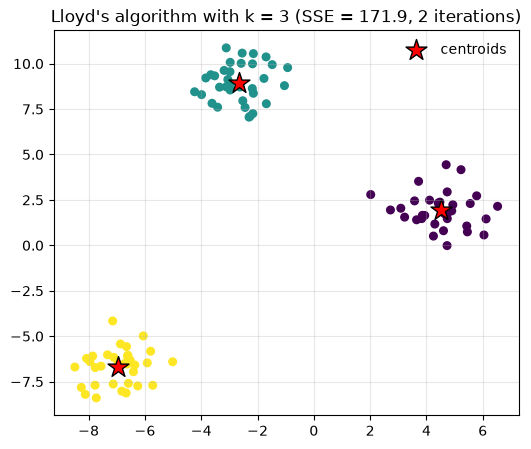

final centroids:
[[ 4.5   1.94]
 [-2.67  8.94]
 [-6.95 -6.68]]


In [2]:
from sklearn.datasets import make_blobs

n_samples = 100
X, y = make_blobs(n_samples=n_samples, centers=3, n_features=2, random_state=SEED)

km = KMeansClustering(k=3).fit(X)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=km.labels, cmap="viridis", s=30)
plt.scatter(km.centroids[:, 0], km.centroids[:, 1], marker="*", s=250, c="red",
            edgecolor="black", label="centroids")
plt.title(f"Lloyd's algorithm with k = 3 (SSE = {km.inertia:.1f}, {km.n_iter_} iterations)")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

print("final centroids:")
print(np.round(km.centroids, 2))

## بررسی عددی لم 2

لم 2 مقدار SSE یک مجموعه نقطه — همان کمیتی که k-means کمینه می‌کند — را برحسب فاصله‌های
*دوبه‌دو* بازنویسی می‌کند:

$$
\sum_{i=1}^n \sum_{j>i} \|\mathbf{x}_i - \mathbf{x}_j\|^2
= n \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
$$

سمت چپ روی همهٔ $\binom{n}{2}$ جفت نقطه جمع می‌زند و سمت راست $n$ برابر مجموع مربع فاصلهٔ نقطه‌ها
تا مرکزشان است. این اتحاد هرجا به کار می‌آید که الگوریتمی فقط به فاصله‌های دوبه‌دو دسترسی داشته
باشد و نه به مختصات.

دقت کنید لم 2 چه چیزی را **نمی‌گوید**: این یک اتحاد است، نه یک گزارهٔ بهینگی. اینکه مرکز مجموع
مربع فاصله‌ها را *کمینه* می‌کند، نتیجهٔ 1 لم 1 است. در ادامه بررسی می‌کنیم که دو طرف لم 2 برای یکی
از خوشه‌های خوشه‌بندی بالا یک عدد می‌دهند.

In [3]:
from scipy.spatial.distance import cdist


def lemma_2(points):
    """Compute both sides of Lemma 2 and report whether they agree."""
    n = len(points)
    centroid = points.mean(axis=0)
    right = n * np.sum((points - centroid) ** 2)
    left = np.sum(cdist(points, points) ** 2) / 2
    print(f"pairwise sum                         = {left:.6f}")
    print(f"n * sum of squared distances to mean = {right:.6f}")
    print(f"relative difference                  = {abs(left - right) / right:.2e}")
    return left, right


points = X[km.labels == 0]
print(f"cluster 0 contains {len(points)} points")
lemma_2(points)

cluster 0 contains 33 points
pairwise sum                         = 2042.432698
n * sum of squared distances to mean = 2042.432698
relative difference                  = 2.23e-16


(np.float64(2042.4326981762324), np.float64(2042.4326981762329))

## آغازش k-means++ (خلاصه)

مقدار آغازین مراکز تعیین می‌کند الگوریتم لوید به کدام کمینهٔ محلی برسد: دو مرکز ممکن است داخل یک
خوشهٔ طبیعی بیفتند و آن را دو نیم کنند، و بعد هیچ تکرار دیگری آن را درست نمی‌کند. **k-means++**
(Arthur و Vassilvitskii، ۲۰۰۷) مراکز آغازین را یکی پس از دیگری انتخاب می‌کند: مرکز اول یکنواخت و
تصادفی از داده، و هر مرکز بعدی با احتمال متناسب با $D(\mathbf{x})^{2}$، که $D$ فاصلهٔ نقطه تا
نزدیک‌ترین مرکز انتخاب‌شده است، تا $k$ مرکز. نقطه‌ای که از مراکز فعلی دور است سهم بیشتری از این توزیع
دارد، پس مراکز در خوشه‌های مختلف پخش می‌شوند و گروهی که هنوز مرکزی ندارد رها نمی‌شود.

تضمین این روش تقریبی است، نه بهینگی: تابع هدف انتظاری اجرا در حد ضریبی $O(\log k)$ از بهینه است
($\mathbb{E}[\mathrm{SSE}] \le 8(\ln k + 2)\,\mathrm{SSE}_{\text{opt}}$)، پس کمینهٔ بد را نامحتمل
می‌کند نه ناممکن؛ به همین دلیل پیاده‌سازی‌ها چند بار راه‌اندازی می‌کنند (`n_init` در scikit-learn) و
اجرای با کمترین SSE را نگه می‌دارند. متن کامل، آزمایش ۱۰۰ اجرا و مقایسه با آغازش تصادفی در
[پیوست](/appendix-clustering-measures-and-variants) آمده است.


## هزینه

هر تکرار $O(nkd)$ است: گام تخصیص $n$ فاصله تا هر یک از $k$ مرکز در فضای $d$-بعدی را حساب می‌کند و
گام به‌روزرسانی هر نقطه را یک بار لمس می‌کند. تعداد تکرارها در عمل کم است (چند ده) ولی کران بدترین
حالتِ سودمندی ندارد، به همین دلیل آن را محدود می‌کنیم. نسخهٔ دقیق را می‌توان با درخت $k$-d یا با
کران‌های نامساوی مثلثی، که بیشتر محاسبه‌های فاصله را رد می‌کنند، سریع‌تر کرد؛ و برای $n$ بزرگ می‌توان
تخصیص دقیق را با یک کوچک‌دستهٔ تصادفی جانشین کرد. هر دو در
[پیوست](/appendix-clustering-measures-and-variants) کار شده‌اند، همراه با آغازش k-means++ که
نسخهٔ پیشین این صفحه داشت.


## مثال: بازیابی بافت تومور با k-means

نظریهٔ بالا می‌گوید k-means چه چیزی را بهینه می‌کند؛ نمی‌گوید پاسخش روی دادهٔ واقعی چه ارزشی دارد.
آزمون کلاسیک آن، دادهٔ میکرواری تومور انسانی در {cite}`hastie2009elements` (بند ۱۴.۳.۸، صص ۵۱۲–۵۱۴)
است که در آن کتاب برای نمایش خوشه‌بندی با ابعاد بالا به کار رفته:

* ماتریس **۶۸۳۰ ژن × ۶۴ نمونه** از اندازه‌گیری‌های بیان ژن است؛
* چیزی که خوشه‌بندی می‌شود **نمونه‌ها** است، پس نمونهٔ $j$ نقطه‌ای در $\mathbb{R}^{6830}$ است و دو
  نمونه وقتی نزدیک‌اند که کل پروفایلشان بخواند، نه وقتی یک ژن بخواند؛
* هر نمونه یک **برچسب آسیب‌شناسی** هم دارد — سینه، CNS، رودهٔ بزرگ، K562، لوسمی، MCF7، ملانوما،
  NSCLC، تخمدان، پروستات، کلیه، نامعلوم — که هنگام خوشه‌بندی **پنهان می‌ماند** و فقط بعد از آن به
  کار می‌آید تا بپرسیم هر خوشه چه چیزی در خود دارد.

نخستین درس این مثال این است که $k$ در داده نیست. اگر مجموع مربع فاصله‌های درون‌خوشه‌ای را برحسب
$K = 1,\ldots,10$ رسم کنیم، زانوی روشنی ندارد (شکل ۱۴.۸ کتاب)، پس $K = 3$ به‌عنوان یک درشت‌نماییِ
عمدی انتخاب می‌شود: یازده نوع بافت در سه جعبه جا داده می‌شود.

اجرای k-means با $K = 3$ و سپس شمردن اینکه کدام برچسب‌ها کجا افتادند، جدول ۱۴.۲ کتاب را می‌دهد —
همان شکلی که هر وقت برچسب وجود دارد باید نتیجه را با آن گزارش کرد، چون هم گروه‌های پاک را نشان
می‌دهد و هم اشتباه‌ها را:

| خوشه | سینه | CNS | رودهٔ بزرگ | K562 | لوسمی | MCF7 | ملانوما | NSCLC | تخمدان | پروستات | کلیه | نامعلوم |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| **۱** | ۳ | ۵ | ۰ | ۰ | ۰ | ۰ | ۱ | ۷ | ۶ | ۲ | ۹ | ۱ |
| **۲** | ۲ | ۰ | ۰ | ۲ | ۶ | ۲ | ۷ | ۲ | ۰ | ۰ | ۰ | ۰ |
| **۳** | ۲ | ۰ | ۷ | ۰ | ۰ | ۰ | ۰ | ۰ | ۰ | ۰ | ۰ | ۰ |

آن را سطری بخوانید. خوشهٔ ۳ عملاً همان سرطان‌های رودهٔ بزرگ است: هر هفت نمونه، به‌علاوهٔ دو نمونهٔ
سینه، و هیچ نمونهٔ رودهٔ بزرگی جای دیگری نیست. خوشهٔ ۲ تومورهای خون و پوست را جمع می‌کند — شش
لوسمی با رده‌های سلولی K562 و MCF7، ملانوماها، و دو نمونهٔ NSCLC. خوشهٔ ۱ باقی مانده است (CNS،
تخمدان، کلیه، پروستات، بیشتر NSCLC)، بزرگ‌ترین و ناخالص‌ترین گروه، که وقتی یازده نوع در سه جعبه
فشرده شود همین انتظار می‌رود. الگوریتم حتی یک برچسب هم ندید.


### این مثال چه ارزشی دارد و چه چیزی را روشن نمی‌کند

آن دو نمونهٔ سینه در خوشهٔ ۲ بعداً معلوم شد **ملانوماهایی با متاستاز** بوده‌اند؛ خوشه‌بندی در برابر
برچسب درست بود. خوب است دقیق باشیم که این یعنی چه: الگوریتم یک *گمان* تولید کرد — این پروفایل‌ها
شبیه آن گروه‌اند، نه شبیه گروهی که برچسبشان ادعا می‌کند — و بررسی آسیب‌شناسی بعداً آن را تأیید کرد.
بدون آن بازبینی، نتیجهٔ صادقانه این بود: «دو نمونه با برچسب خود ناسازگارند، به دلایلی نامعلوم». یادگیری
بی‌نظارت می‌تواند در برابر برچسب‌ها درست باشد، ولی فقط یک پیگیری این را به دانش تبدیل می‌کند.

دو محدودیت روش در همان جدول دیده می‌شود:

* **ترتیبی درون خوشه نیست:** خوشهٔ ۱ را فقط می‌شود الفبایی فهرست کرد، و این هیچ نمی‌گوید کدام
  اعضایش بیشتر به هم شبیه‌اند؛
* **تودرتویی بین $K$ها نیست:** جواب $K = 4$ لزوماً ریزترکردن جواب $K = 3$ نیست، پس جدولی که برای
  یک $K$ ساخته شده با تغییر تعداد گروه‌ها گسترش‌پذیر نیست.

هر دو با یک تغییر در شکل گزارش درمان می‌شوند: دندروگرام نمونه‌ها را روی یک خط مرتب می‌کند و
خانواده‌ای تودرتو از افرازها می‌دهد؛ به همین دلیل کتاب برای این کاربرد خوشه‌بندی سلسله‌مراتبی را
ترجیح می‌دهد. باقی ماجرا احتیاط‌های $n$ کوچک است: با $n = 64$ یک نمونهٔ نامتعارف مرکزی را جابه‌جا
می‌کند و جدول را دیدنی عوض می‌کند، انتخاب ژن‌ها و پیش‌پردازش همهٔ فاصله‌ها را جابه‌جا می‌کند، و یک
اجرای تنها با آغازش تصادفی چیزی را ثابت نمی‌کند — نگهبان کار چند راه‌اندازی دوباره است، یا آغازش
بهترِ کارشده در [پیوست](/appendix-clustering-measures-and-variants).


## جمع‌بندی

* k-means تابع SSE یعنی $\sum_{i=1}^{k}\sum_{\mathbf{x}\in C_i}\|\mathbf{x}-\mu_i\|^2$ را روی
  افرازها به $k$ خوشهٔ ناتهی کمینه می‌کند.
* لم 1 مجموع مربع فاصله‌ها تا یک نقطهٔ دلخواه $z$ را تجزیه می‌کند؛ نتیجهٔ آن، مرکز را به‌عنوان
  یکتای کمینه‌کننده معرفی می‌کند و همین گام به‌روزرسانی را توجیه می‌کند.
* لم 2 همان SSE را برحسب فاصله‌های دوبه‌دو بازنویسی می‌کند. این یک اتحاد است، نه گزارهٔ بهینگی.
* الگوریتم لوید تخصیص و به‌روزرسانی را یکی در میان انجام می‌دهد، پس SSE هرگز زیاد نمی‌شود؛ دنبالهٔ
  نامنظم روی مجموعهٔ متناهی افرازها باید متوقف شود، و در یک کمینهٔ محلی متوقف می‌شود.
* نتیجه به آغازش بستگی دارد، پس پیاده‌سازی‌ها کل روش را چند بار تکرار می‌کنند و اجرای با کمترین
  SSE را نگه می‌دارند؛ k-means++ و آزمایش پشتش در
  [پیوست](/appendix-clustering-measures-and-variants) آمده‌اند.
* در مثال میکرواری تومور، k-means بدون دیدن هیچ برچسبی بافت منشأ را بازیابی می‌کند، و نتیجه همان
  جدول توافقی است، نه خود خوشه‌ها.
* انتخاب $k$ مسئلهٔ جدایی است که در [اعتبارسنجی خوشه‌بندی](Clustering-Validation.ipynb) بررسی
  می‌شود.

## مطالب اختیاری دربارهٔ k-means

* [Data clustering: 50 years beyond K-means - ScienceDirect](https://www.sciencedirect.com/science/article/abs/pii/S0167865509002323)
* [K-Means Factorizaton](https://www.dropbox.com/s/2fsmpj7i7x3rngy/K-Means%20Factorizaton1512.07548.pdf?dl=1)  
* [Balanced K-Means for Clustering | SpringerLink](https://link.springer.com/chapter/10.1007/978-3-662-44415-3_4)
* [M. Amintoosi, (2002) Student’s sectioning using fuzzy inference system (In Persian)](https://www.dropbox.com/s/7ohrff9c6im8bye/1382-StudentSectioning.pdf?dl=1)
* [SE Question: Minimizing the sum of distances between points and a point on the plane?](https://math.stackexchange.com/questions/3037564/minimizing-the-sum-of-distances-between-points-and-a-point-on-the-plane)
* [Geometric Median](https://en.wikipedia.org/wiki/Geometric_median)
* [Weiszfeld's algorithm (Andrew Vázsonyi)](https://en.wikipedia.org/wiki/Andrew_V%C3%A1zsonyi)

## بقیهٔ مطالب کجاست

دو صفحهٔ پیوست بخش‌هایی از این موضوع را دارند که اینجا جا نشدند:

* [پیوست: سنجه‌های بیشتر خوشه‌بندی و گونه‌های k-means](/appendix-clustering-measures-and-variants)
  — NMI و مشکل تصحیح‌نشدنش برای شانس، آمارهٔ شکاف که زانو را به یک تصمیم تبدیل می‌کند، مسئلهٔ
  تخصیص پشت امتیاز جفت‌سازی بیشینه، آغازش k-means++ همراه آزمایش ۱۰۰ اجرایش، و mini-batch k-means
  با مقایسهٔ زمانش با نسخهٔ دقیق.
* [پیوست: چرا k-means با مشتق‌گیری حل نمی‌شود](Appendix-k-Means-Differentiation.md)
  — همان تابع هدف، این بار با مشتق‌گیری باز می‌شود: مشتق نسبت به مرکز، گام تخصیص که در $z_{ij}$
  خطی است و کمینه‌اش روی رأس رخ می‌دهد، اینکه تناوب این دو گام همان الگوریتم لوید است، شکل ماتریسی
  و پیش‌نمایش معادلات نرمال رگرسیون، و یک پیاده‌سازی روی Iris که همهٔ فرمول‌ها را عددی چک می‌کند.

هر دو پیوست فعلاً فقط به انگلیسی هستند.
